# Лабораторная работа 4. Attention с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Реализовать scaled dot-product и multi-head attention, вывести обратный проход вручную и экспериментально проверить роль масштабирования $1/\sqrt{d_k}$, масок и позиционной информации.

**Что нужно сдать:**
1. Модуль attention (каузальная и padding-маски), совпадающий с `F.scaled_dot_product_attention` с точностью 1e-5.
2. Ручной backward attention, сверенный с autograd.
3. Эксперимент с масштабированием: энтропия attention и нормы градиентов при разных $d_k$, кривые обучения.
4. Решение трёх синтетических задач и визуализацию карт внимания.
5. Проверку перестановочной эквивариантности.

**Теория.** $\mathrm{Attn}(Q,K,V) = \mathrm{softmax}\big(QK^\top/\sqrt{d_k} + M\big)V$. Если компоненты $q, k$ независимы, с нулевым средним и единичной дисперсией, то $\mathrm{Var}(q^\top k) = d_k$, поэтому без масштабирования логиты растут как $\sqrt{d_k}$, softmax насыщается, а его якобиан $\operatorname{diag}(p) - pp^\top$ стремится к нулю.

Обратный проход для $S = QK^\top/\sqrt{d}$, $P = \mathrm{softmax}(S)$, $O = PV$:
$$
dV = P^\top dO,\quad dP = dO\,V^\top,\quad dS = P \odot \big(dP - \mathrm{rowsum}(dP \odot P)\big),\quad dQ = \tfrac{1}{\sqrt d}\, dS\, K,\quad dK = \tfrac{1}{\sqrt d}\, dS^\top Q .
$$

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.8.0.dev20250625+cu128, device=cuda, FAST_DEV_RUN=True


## 1. Scaled dot-product attention и маски

Соглашения: `q, k, v` имеют форму `(B, H, T, d)`; `key_padding_mask` — булев тензор `(B, T)`, `True` означает «паддинг, не смотреть». Замаскированные логиты заменяйте на $-\infty$. Если строка замаскирована полностью, результат не определён: в тестах таких строк нет.

In [2]:
def sdpa(q, k, v, causal=False, key_padding_mask=None, scale=None, return_probs=False):
    d = q.size(-1)
    scale = 1 / math.sqrt(d) if scale is None else scale
    # TODO: ваш код
    
    logits = q @ k.transpose(-2, -1) * scale
    
    if causal:
        Tq = q.size(-2)
        Tk = k.size(-2)

        causal_mask = torch.ones(
            Tq,
            Tk,
            dtype=torch.bool,
            device=q.device,
        ).triu(diagonal=1)

        logits = logits.masked_fill(
            causal_mask,
            float("-inf"),
        )
    
    if key_padding_mask is not None:
        mask = key_padding_mask[:, None, None, :]
        logits = logits.masked_fill(mask, float("-inf"))
        
    p = logits.softmax(dim=-1)
    return (p @ v, p) if return_probs else p @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_head, causal=False, scale=None):
        super().__init__()
        assert d_model % n_head == 0
        self.h, self.d = n_head, d_model // n_head
        self.wq, self.wk, self.wv, self.wo = (nn.Linear(d_model, d_model, bias=False) for _ in range(4))
        self.causal, self.scale = causal, scale
        self.last_probs = None
    def forward(self, x, key_padding_mask=None):
        B, T, C = x.shape
        q = (
            self.wq(x)
            .view(B, T, self.h, self.d)
            .transpose(1, 2)
        )
        k = (
            self.wk(x)
            .view(B, T, self.h, self.d)
            .transpose(1, 2)
        )
        v = (
            self.wv(x)
            .view(B, T, self.h, self.d)
            .transpose(1, 2)
        )

        out, p = sdpa(
            q,
            k,
            v,
            causal=self.causal,
            key_padding_mask=key_padding_mask,
            scale=self.scale,
            return_probs=True,
        )

        self.last_probs = p.detach()

        out = out.transpose(1, 2).reshape(B, T, C)

        out = self.wo(out)

        return out

In [3]:
torch.manual_seed(0)
q, k, v = (torch.randn(2, 3, 7, 16) for _ in range(3))
pad = torch.zeros(2, 7, dtype=torch.bool); pad[1, 5:] = True
for causal in (False, True):
    ref = F.scaled_dot_product_attention(q, k, v, is_causal=causal)
    assert torch.allclose(sdpa(q, k, v, causal), ref, atol=1e-5)
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=~pad[:, None, None, :])
assert torch.allclose(sdpa(q, k, v, key_padding_mask=pad), ref, atol=1e-5)
print("sdpa совпадает с F.scaled_dot_product_attention")

sdpa совпадает с F.scaled_dot_product_attention


## 2. Ручной обратный проход

Реализуйте `sdpa_backward`, получающий `q, k, v, dO` и возвращающий `dq, dk, dv`. Используйте формулы из введения; маски учитываются автоматически, так как $P = 0$ в замаскированных позициях.

In [17]:
def sdpa_backward(q, k, v, dO, causal=False):
    d = q.size(-1); scale = 1 / math.sqrt(d)
    _, P = sdpa(q, k, v, causal, return_probs=True)
    # TODO: ваш код

    dv = P.transpose(-2, -1) @ dO
    dP = dO @ v.transpose(-2, -1)
    dS = P * (dP - (P*dP).sum(axis = -1, keepdim = True))
    
    
    dq = scale * dS @ k
    dk = scale * dS.transpose(-2, -1) @ q
        
    return dq, dk, dv
    
q, k, v = (torch.randn(2, 3, 6, 8, dtype=torch.float64, requires_grad=True) for _ in range(3))
dO = torch.randn(2, 3, 6, 8, dtype=torch.float64)
for causal in (False, True):
    for t in (q, k, v): t.grad = None
    (sdpa(q, k, v, causal) * dO).sum().backward()
    ours = sdpa_backward(q.detach(), k.detach(), v.detach(), dO, causal)
    for name, a, b in zip("qkv", ours, (q.grad, k.grad, v.grad)):
        assert torch.allclose(a, b, atol=1e-10), name
print("Ручной backward совпадает с autograd (с маской и без)")

Ручной backward совпадает с autograd (с маской и без)


## 3. Зачем делить на $\sqrt{d_k}$

**3а. Анализ при инициализации.** Для $q, k \sim \mathcal{N}(0, I_{d_k})$, $T = 128$ и $d_k \in \{8, 32, 128, 512\}$ измерьте при масштабах $1$, $1/\sqrt{d_k}$, $1/d_k$:
- дисперсию логитов;
- среднюю энтропию строк attention (в сравнении с $\log T$);
- норму якобиана softmax $\|\operatorname{diag}(p) - pp^\top\|_F$, усреднённую по строкам.

In [18]:
def softmax_jacobian_norm(p):
    """p: (..., T) — строки вероятностей; возвращает среднюю норму Фробениуса якобиана softmax."""
    # TODO: ваш код
    diag_p = torch.diag_embed(p)
    outer_p = p.unsqueeze(-1) * p.unsqueeze(-2)

    J = diag_p - outer_p

    norms = torch.linalg.matrix_norm(
        J,
        ord="fro",
        dim=(-2, -1),
    )

    return norms.mean().item()

T = 128; rows = []
for dk in (8, 32, 128, 512):
    q, k = torch.randn(64, T, dk), torch.randn(64, T, dk)
    for name, sc in [("1", 1.0), ("1/sqrt(d)", dk ** -0.5), ("1/d", 1 / dk)]:
        s = (q @ k.transpose(-1, -2)) * sc; p = s.softmax(-1)
        ent = -(p * torch.log(p + 1e-12)).sum(-1).mean().item()
        rows.append({"d_k": dk, "масштаб": name, "Var(логитов)": s.var().item(), "энтропия/log T": ent / math.log(T),
                     "||J_softmax||": softmax_jacobian_norm(p[:8])})
import pandas as pd
pd.DataFrame(rows).pivot(index="d_k", columns="масштаб").round(3)

Var(логитов)                  энтропия/log T                   \
масштаб            1    1/d 1/sqrt(d)              1    1/d 1/sqrt(d)   
d_k                                                                     
8              8.015  0.125     1.002          0.513  0.987     0.901   
32            31.961  0.031     0.999          0.216  0.997     0.900   
128          127.933  0.008     0.999          0.089  0.999     0.900   
512          511.381  0.002     0.999          0.042  1.000     0.900   

        ||J_softmax||                   
масштаб             1    1/d 1/sqrt(d)  
d_k                                     
8               0.274  0.094     0.135  
32              0.274  0.089     0.136  
128             0.165  0.088     0.137  
512             0.091  0.088     0.136

**3б. Обучение.** Обучите двухслойную attention-модель на задаче ассоциативного поиска (п. 4) с тремя вариантами масштаба при $d_{head} = 64$ и сравните кривые обучения. Чтобы эффект проявился, инициализируйте проекции $W_Q, W_K$ так, чтобы $q, k$ имели единичную дисперсию (`std = 1/sqrt(d_model)`), как в анализе выше.

## 4. Синтетические задачи

Модель: эмбеддинги токенов + обучаемые позиционные эмбеддинги, $L$ слоёв `x = x + MHA(LN(x))` (без MLP), выходная голова.

1. **Копирование:** выход в позиции $i$ равен входу $x_i$ (1 слой, без каузальной маски) — санити-чек.
2. **Разворот:** выход в позиции $i$ равен $x_{T-1-i}$ (1 слой, без маски) — требует позиционной информации.
3. **Ассоциативный поиск:** вход `k1 v1 k2 v2 … kn vn q`, где $q$ совпадает с одним из ключей; предсказать соответствующее значение (2 слоя, каузальная маска). Это минимальная версия механизма induction heads.

In [ ]:
class AttnOnly(nn.Module):
    def __init__(self, vocab, T, d_model=128, n_head=2, n_layer=1, causal=False, scale=None, qk_unit_init=False, use_pos=True):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_model); self.pos = nn.Parameter(torch.randn(T, d_model) * 0.02) if use_pos else None
        self.layers = nn.ModuleList([MultiHeadAttention(d_model, n_head, causal, scale) for _ in range(n_layer)])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.head = nn.Linear(d_model, vocab)
        if qk_unit_init:
            for l in self.layers:
                for w in (l.wq, l.wk): nn.init.normal_(w.weight, 0, d_model ** -0.5)
    def forward(self, x):
        h = self.emb(x) + (self.pos[: x.size(1)] if self.pos is not None else 0)
        for ln, attn in zip(self.norms, self.layers): h = h + attn(ln(h))
        return self.head(h)

def task_batch(task, B=128, T=16, vocab=32):
    if task in ("copy", "reverse"):
        x = torch.randint(vocab, (B, T)); y = x if task == "copy" else x.flip(1)
        return x, y, torch.ones(B, T, dtype=torch.bool)
    # TODO: ваш код (ключи из [0, vocab/2), значения из [vocab/2, vocab); ключи в примере различны; loss только на последней позиции)
    if task == "assoc":
        key_vocab = vocab // 2
        n = (T - 1) // 2

        keys = torch.stack([
            torch.randperm(key_vocab)[:n]
            for _ in range(B)
        ])

        values = torch.randint(
            key_vocab,
            vocab,
            (B, n),
        )

        chosen = torch.randint(n, (B,))
        batch_indices = torch.arange(B)

        query = keys[batch_indices, chosen]
        target = values[batch_indices, chosen]

        x = torch.empty(
            B,
            2 * n + 1,
            dtype=torch.long,
        )
        x[:, 0:2 * n:2] = keys
        x[:, 1:2 * n:2] = values
        x[:, -1] = query

        y = torch.zeros_like(x)
        y[:, -1] = target

        m = torch.zeros_like(x, dtype=torch.bool)
        m[:, -1] = True

        return x, y, m


def train_task(model, task, steps, lr=1e-3, T=16):
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    for s in range(steps):
        x, y, m = task_batch(task, T=T)
        logits = model(x); loss = F.cross_entropy(logits[m], y[m])
        opt.zero_grad(); loss.backward(); opt.step()
        if s % 25 == 0 or s == steps - 1:
            with torch.no_grad():
                x, y, m = task_batch(task, B=512, T=T); acc = (model(x).argmax(-1)[m] == y[m]).float().mean().item()
            hist.append((s, loss.item(), acc))
    return hist

STEPS = 400 if FAST_DEV_RUN else 3000
results = {}
for task, L, causal in [("copy", 1, False), ("reverse", 1, False), ("assoc", 2, True)]:
    set_seed(); m = AttnOnly(32, 16, n_layer=L, causal=causal)
    results[task] = (m, train_task(m, task, STEPS if task != "assoc" else 2 * STEPS))
    print(f"{task:8s} итоговая точность = {results[task][1][-1][2]:.3f}")

copy     итоговая точность = 1.000
reverse  итоговая точность = 1.000
assoc    итоговая точность = 1.000


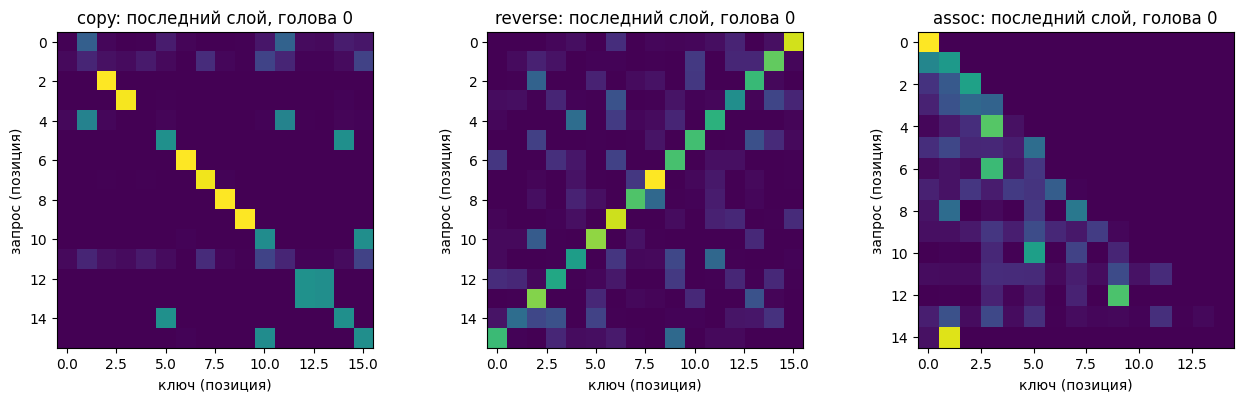

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, task in zip(axes, ["copy", "reverse", "assoc"]):
    m = results[task][0]; x, _, _ = task_batch(task, B=1)
    with torch.no_grad(): m(x)
    ax.imshow(m.layers[-1].last_probs[0, 0], cmap="viridis"); ax.set_title(f"{task}: последний слой, голова 0")
    ax.set_xlabel("ключ (позиция)"); ax.set_ylabel("запрос (позиция)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab04_attention_maps.png", dpi=120); plt.show()

### 3б. Масштабирование в обучении

In [ ]:
d_head = 64

scales = {
    "1": 1.0,
    "1/sqrt(d)": d_head ** -0.5,
    "1/d": 1 / d_head,
}

scale_results = {}

for name, scale in scales.items():
    set_seed()

    model = AttnOnly(
        vocab=32,
        T=16,
        d_model=128,
        n_head=2,
        n_layer=2,
        causal=True,
        scale=scale,
        qk_unit_init=True,
    )

    history = train_task(
        model=model,
        task="assoc",
        steps=2 * STEPS,
        T=16,
    )

    scale_results[name] = {
        "model": model,
        "history": history,
    }

    final_step, final_loss, final_accuracy = history[-1]

    print(
        f"{name:10s} | "
        f"step={final_step:4d} | "
        f"loss={final_loss:.4f} | "
        f"accuracy={final_accuracy:.3f}"
    )

1          | step= 799 | loss=2.3850 | accuracy=0.189
1/sqrt(d)  | step= 799 | loss=0.0002 | accuracy=1.000
1/d        | step= 799 | loss=0.0003 | accuracy=1.000


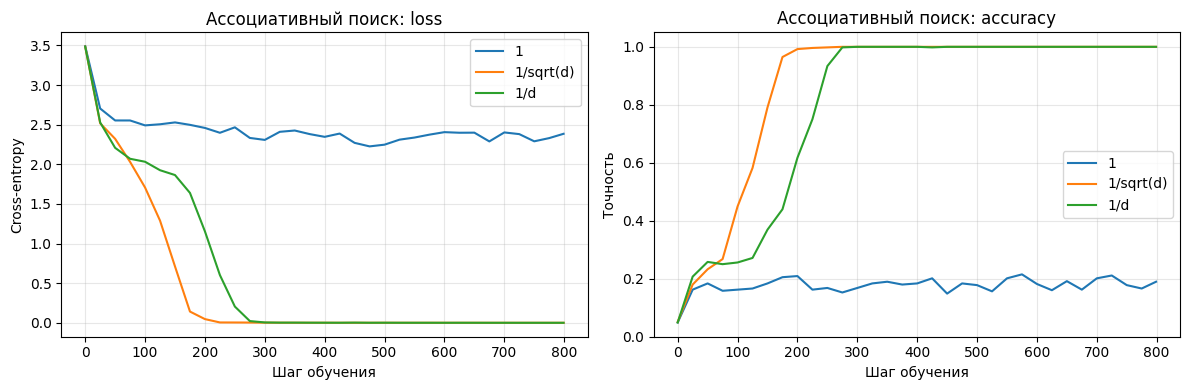

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, result in scale_results.items():
    history = result["history"]

    steps, losses, accuracies = zip(*history)

    axes[0].plot(
        steps,
        losses,
        label=name,
    )

    axes[1].plot(
        steps,
        accuracies,
        label=name,
    )

axes[0].set_title("Ассоциативный поиск: loss")
axes[0].set_xlabel("Шаг обучения")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Ассоциативный поиск: accuracy")
axes[1].set_xlabel("Шаг обучения")
axes[1].set_ylabel("Точность")
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig(
    ARTIFACTS / "lab04_scale_training.png",
    dpi=120,
)
plt.show()

## 5. Перестановочная эквивариантность

Проверьте, что без позиционных эмбеддингов и без каузальной маски слой attention эквивариантен к перестановкам: $f(\Pi X) = \Pi f(X)$. Покажите, что с позиционными эмбеддингами или с каузальной маской это свойство нарушается, и объясните, почему без позиционной информации задача разворота не решается.

In [ ]:
set_seed()
B, T, vocab = 4, 12, 32
x = torch.randint(vocab, (B, T))
perm = torch.randperm(T)

# Базовая модель: без позиционных эмбеддингов и без каузальной маски.
base = AttnOnly(vocab, T, d_model=64, n_head=4, n_layer=1, causal=False, use_pos=False).eval()

# Две модели с теми же общими весами, но с позициями или каузальной маской.
with_pos = AttnOnly(vocab, T, d_model=64, n_head=4, n_layer=1, causal=False, use_pos=True).eval()
with_pos.load_state_dict(base.state_dict(), strict=False)  # pos остаётся своим

with_causal = AttnOnly(vocab, T, d_model=64, n_head=4, n_layer=1, causal=True, use_pos=False).eval()
with_causal.load_state_dict(base.state_dict())

@torch.no_grad()
def equivariance_error(model):
    # f(ΠX) сравниваем с Πf(X).
    f_permuted_x = model(x[:, perm])
    permuted_f_x = model(x)[:, perm]
    return (f_permuted_x - permuted_f_x).abs().max().item()

errors = {
    "без позиций и маски": equivariance_error(base),
    "с позиционными эмбеддингами": equivariance_error(with_pos),
    "с каузальной маской": equivariance_error(with_causal),
}

for name, error in errors.items():
    print(f"{name:28s}: max |f(ΠX) - Πf(X)| = {error:.3e}")

assert errors["без позиций и маски"] < 1e-5
assert errors["с позиционными эмбеддингами"] > 1e-5
assert errors["с каузальной маской"] > 1e-5

print("Без позиционной информации модель не знает индексы токенов, поэтому не может реализовать разворот i → T - 1 - i.")

## Вопросы

1. Докажите, что $\mathrm{Var}(q^\top k) = d_k$ при сделанных предположениях. Какие предположения нарушаются в обученной модели?
2. Почему насыщение softmax вредно именно для обучения, а не для инференса?
3. Почему для разворота достаточно одного слоя, а для ассоциативного поиска с каузальной маской нужно два? Опишите механизм, который реализуют два слоя.
4. Какую сложность по времени и памяти имеет ваша реализация? Какие промежуточные тензоры приходится хранить для обратного прохода?
5. Объясните на основе эксперимента 3б, почему масштаб $1/d$ (μP-attention) тоже может работать.